# Aula 5 — Algoritmo Genético
## Trabalho: Alocação de Grade de Disciplinas

**Aluno:** Leonardo Teixeira — **RA:** 245602 — Mineração de Dados (UNICAMP)

**Objetivo:** montar uma grade semanal (segunda a sexta, uma disciplina por dia) com o menor custo possível, usando um algoritmo genético (AG), conforme o enunciado *Projeto Algoritmo Genético — Alocação de Grade de Disciplinas*.

**Resumo do problema (enunciado):**
- 10 professores, cada um com um custo por aula e um conjunto de disciplinas que já ministrou; disciplinas numeradas de 1 a 20; 5 dias de aula, uma disciplina por dia.
- Cromossomo: `[P,D , P,D , P,D , P,D , P,D]` (Seg, Ter, Qua, Qui, Sex), com P ∈ [1, 10] e D ∈ [1, 20].
- Função de fitness (minimização):
  F = (×2, se algum professor nunca ministrou a disciplina alocada) × (×1,5, se algum professor é escolhido para mais de uma disciplina) × (×5, se a mesma disciplina aparece em dias diferentes) × (custo_seg + custo_ter + custo_qua + custo_qui + custo_sex).
- Cromossomo inicial `[3,2 , 8,9 , 1,12 , 10,14 , 8,4]`; população de 60 indivíduos; elitismo de 20%; mutação de 10% (1 gene por vez); crossover com o cromossomo partido em duas partes, em posição variável; limite de 500 gerações.

**Roteiro do notebook:**

| Seção | Conteúdo | Item do enunciado |
|---|---|---|
| 1 | Dados: `tab_professores.txt` e leitura para dicionário | 1 e 2 |
| 2 | Modelagem do cromossomo | Passo 1 |
| 3 | Função de fitness | 3 |
| 4 | Mutação e cruzamento | 4 |
| 5 | Algoritmo genético | 5 |
| 6 | Ótimo global do problema (referência para avaliar o AG) | — |
| 7 | Execução com a configuração oficial | 6 |
| 8 | Estudo de parâmetros com 30 sementes | 7 |
| 9 | Configuração proposta × configuração oficial | 8 |
| 10 | Conclusão | — |

## 1. Dados (itens 1 e 2)

O arquivo `tab_professores.txt` foi montado transcrevendo a tabela de professores do enunciado, uma linha por professor, no formato pedido: `professor, custo, disciplina1, disciplina2, ...` (ex.: `1,89,1,3,6,8,12,15,17,20`). As 10 linhas foram conferidas contra a tabela original, célula a célula.

A leitura preenche um dicionário no formato `{professor: {"custo": ..., "disciplinas": {...}}}`. O arquivo fica em `data/tab_professores.txt`, com caminho relativo à pasta deste notebook.

In [1]:
import random
import statistics
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import fisher_exact, wilcoxon

pd.set_option("display.max_columns", None)

ARQUIVO_PROFESSORES = Path("data") / "tab_professores.txt"


def carregar_professores(caminho):
    professores = {}
    with open(caminho, encoding="utf-8") as arquivo:
        for linha in arquivo:
            if not linha.strip():
                continue
            professor, custo, *disciplinas = (int(v) for v in linha.split(",") if v.strip())
            professores[professor] = {"custo": custo, "disciplinas": set(disciplinas)}
    return professores


professores = carregar_professores(ARQUIVO_PROFESSORES)

display(pd.DataFrame(
    [(p, info["custo"], ", ".join(map(str, sorted(info["disciplinas"])))) for p, info in professores.items()],
    columns=["Professor", "Custo (R$)", "Disciplinas que já ministrou"],
).set_index("Professor"))

,Custo (R$),Disciplinas que já ministrou
Professor,,
1,89,"1, 3, 6, 8, 12, 15, 17, 20"
2,80,"2, 10, 14, 19"
3,60,"2, 4, 6, 9, 11, 13, 15, 17"
4,50,"1, 5, 10, 18"
5,85,"3, 5, 6, 9, 10, 12, 15, 17"
6,65,"12, 13, 15, 16, 19, 20"
7,70,"2, 3, 5, 8, 11, 17"
8,69,"1, 4, 7, 9, 11, 15"
9,88,"1, 3, 4, 5, 6, 7, 10, 12, 13, 14, 16, 17, 19, 20"


## 2. Modelagem do cromossomo

- O cromossomo tem 10 genes, formando 5 pares `(P, D)` — um par por dia, de segunda a sexta.
- Posições pares (0, 2, 4, 6, 8): **professor**, domínio [1, 10].
- Posições ímpares (1, 3, 5, 7, 9): **disciplina**, domínio [1, 20].

In [2]:
DIAS_SEMANA = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta"]
NUM_DIAS = len(DIAS_SEMANA)          # 5 pares (P, D) -> 10 genes
NUM_PROFESSORES = len(professores)   # domínio de P: [1, 10]
NUM_DISCIPLINAS = 20                 # domínio de D: [1, 20], conforme o enunciado

cromossomo_inicial = [3, 2, 8, 9, 1, 12, 10, 14, 8, 4]  # dado no enunciado


def pares(cromossomo):
    return [(cromossomo[2 * i], cromossomo[2 * i + 1]) for i in range(NUM_DIAS)]


print(f"Número de genes: {len(cromossomo_inicial)}")
for dia, (p, d) in zip(DIAS_SEMANA, pares(cromossomo_inicial)):
    print(f"  {dia:8s}: professor {p:2d}, disciplina {d:2d}")

Número de genes: 10
  Segunda : professor  3, disciplina  2
  Terça   : professor  8, disciplina  9
  Quarta  : professor  1, disciplina 12
  Quinta  : professor 10, disciplina 14
  Sexta   : professor  8, disciplina  4


## 3. Função de fitness (item 3)

A implementação segue a função de fitness definida no enunciado oficial da atividade:

F = (×2 se algum professor nunca ministrou a disciplina alocada) × (×1,5 se algum professor aparece em mais de um dia) × (×5 se alguma disciplina aparece em mais de um dia) × (soma dos custos dos 5 dias)

Duas leituras do enunciado orientam o código:

1. **O custo de cada dia é o custo do professor alocado** (o custo é por professor; ex. do enunciado: professor 3 na segunda → R\$ 60,00). Quando o professor nunca ministrou a disciplina, isso é penalizado pelo fator ×2, e o custo do dia continua sendo o custo dele.
2. **Cada fator é aplicado uma vez quando sua condição ocorre** (a fórmula traz um fator por tipo de condição). Os três fatores podem ocorrer ao mesmo tempo, e então se multiplicam (ex.: ×2 × 1,5 = ×3).

Quanto menor F, melhor a solução. As funções `tabela_grade` e `tabela_fitness` apenas exibem a solução, dia a dia e fator a fator.

In [3]:
def fatores_penalidade(cromossomo, professores):
    dias = pares(cromossomo)
    nao_qualificado = any(d not in professores[p]["disciplinas"] for p, d in dias)
    professor_repetido = len({p for p, _ in dias}) < NUM_DIAS
    disciplina_repetida = len({d for _, d in dias}) < NUM_DIAS
    return (2.0 if nao_qualificado else 1.0,
            1.5 if professor_repetido else 1.0,
            5.0 if disciplina_repetida else 1.0)


def custo_base(cromossomo, professores):
    return sum(professores[p]["custo"] for p, _ in pares(cromossomo))


def funcao_fitness(cromossomo, professores):
    fator_nunca_ministrou, fator_prof_repetido, fator_disc_repetida = fatores_penalidade(cromossomo, professores)
    return fator_nunca_ministrou * fator_prof_repetido * fator_disc_repetida * custo_base(cromossomo, professores)


def tabela_grade(cromossomo, professores):
    dias = pares(cromossomo)
    lista_p = [p for p, _ in dias]
    lista_d = [d for _, d in dias]
    linhas = []
    for dia, (p, d) in zip(DIAS_SEMANA, dias):
        penalizacoes = []
        if d not in professores[p]["disciplinas"]:
            penalizacoes.append("professor nunca ministrou (×2)")
        if lista_p.count(p) > 1:
            penalizacoes.append("professor repetido (×1,5)")
        if lista_d.count(d) > 1:
            penalizacoes.append("disciplina repetida (×5)")
        linhas.append({"Dia": dia, "Professor": p, "Disciplina": d,
                       "Custo (R$)": professores[p]["custo"],
                       "Penalizações": "; ".join(penalizacoes) or "—"})
    return pd.DataFrame(linhas).set_index("Dia")


def tabela_fitness(cromossomo, professores):
    f2, f15, f5 = fatores_penalidade(cromossomo, professores)
    return pd.DataFrame([{
        "Custo base (R$)": custo_base(cromossomo, professores),
        "Fator ×2 (nunca ministrou)": f2,
        "Fator ×1,5 (prof. repetido)": f15,
        "Fator ×5 (disc. repetida)": f5,
        "Fitness F": funcao_fitness(cromossomo, professores),
    }], index=["valor"])


print("Cromossomo inicial do enunciado:", cromossomo_inicial)
display(tabela_grade(cromossomo_inicial, professores))
display(tabela_fitness(cromossomo_inicial, professores))

Cromossomo inicial do enunciado: [3, 2, 8, 9, 1, 12, 10, 14, 8, 4]


,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,3,2,60,—
Terça,8,9,69,"professor repetido (×1,5)"
Quarta,1,12,89,—
Quinta,10,14,76,professor nunca ministrou (×2)
Sexta,8,4,69,"professor repetido (×1,5)"


,Custo base (R$),Fator ×2 (nunca ministrou),"Fator ×1,5 (prof. repetido)",Fator ×5 (disc. repetida),Fitness F
valor,363,2.0,1.5,1.0,1089.0


## 4. Mutação e cruzamento (item 4)

**Mutação — 1 gene por vez.** O exemplo do enunciado muda um único gene, de 5 para 8 (4º elemento: disciplina da terça). É um salto dentro do domínio, e não um passo de ±1. Por isso, a mutação sorteia 1 posição e a substitui por um **valor diferente do atual**, dentro do domínio daquele gene: professor em [1, 10] nas posições pares, disciplina em [1, 20] nas ímpares. Excluir o valor atual garante que cada mutação altere exatamente 1 gene.

**Cruzamento — cromossomo partido em duas partes, em posição variável.** Um ponto de corte é sorteado entre 1 e 9 (qualquer posição que gere duas partes não vazias). Como no exemplo do enunciado, são gerados os dois filhos: o 1º recebe a parte inicial do pai 1 e a final do pai 2, e o 2º o inverso.

A célula de verificação abaixo: (1) reproduz exatamente o exemplo de cruzamento do enunciado (quebra no 6º elemento); e (2) aplica 10.000 mutações para confirmar que sempre exatamente 1 gene muda, dentro do domínio. Como o cruzamento só recombina genes já válidos e a mutação respeita o domínio, o AG nunca gera professor ou disciplina fora do intervalo.

In [4]:
def mutacao(cromossomo):
    posicao = random.randrange(len(cromossomo))
    limite = NUM_PROFESSORES if posicao % 2 == 0 else NUM_DISCIPLINAS  # par: professor | ímpar: disciplina
    mutante = cromossomo[:]
    mutante[posicao] = random.choice([v for v in range(1, limite + 1) if v != cromossomo[posicao]])
    return mutante


def cruzamento(pai1, pai2, corte=None):
    if corte is None:
        corte = random.randint(1, len(pai1) - 1)
    return pai1[:corte] + pai2[corte:], pai2[:corte] + pai1[corte:]


def gerar_individuo_aleatorio():
    individuo = []
    for _ in range(NUM_DIAS):
        individuo += [random.randint(1, NUM_PROFESSORES), random.randint(1, NUM_DISCIPLINAS)]
    return individuo

In [5]:
# (1) exemplo de cruzamento do enunciado, com quebra no 6º elemento
cr1 = [2, 6, 6, 5, 7, 7, 9, 19, 4, 20]
cr2 = [3, 8, 7, 1, 10, 2, 3, 1, 7, 3]
filho1, filho2 = cruzamento(cr1, cr2, corte=6)
print("Filho 1:", filho1, "| enunciado:", [2, 6, 6, 5, 7, 7, 3, 1, 7, 3])
print("Filho 2:", filho2, "| enunciado:", [3, 8, 7, 1, 10, 2, 9, 19, 4, 20])
assert filho1 == [2, 6, 6, 5, 7, 7, 3, 1, 7, 3] and filho2 == [3, 8, 7, 1, 10, 2, 9, 19, 4, 20]

# (2) 10.000 mutações: exatamente 1 gene alterado, sempre dentro do domínio
# (esta semente não afeta os experimentos: cada execução do AG fixa a sua própria semente)
random.seed(0)
for _ in range(10_000):
    original = gerar_individuo_aleatorio()
    mutante = mutacao(original)
    alterados = [i for i in range(len(original)) if original[i] != mutante[i]]
    assert len(alterados) == 1
    i = alterados[0]
    assert 1 <= mutante[i] <= (NUM_PROFESSORES if i % 2 == 0 else NUM_DISCIPLINAS)
print("Mutação: 10.000 testes — sempre exatamente 1 gene alterado, dentro do domínio.")

Filho 1: [2, 6, 6, 5, 7, 7, 3, 1, 7, 3] | enunciado: [2, 6, 6, 5, 7, 7, 3, 1, 7, 3]
Filho 2: [3, 8, 7, 1, 10, 2, 9, 19, 4, 20] | enunciado: [3, 8, 7, 1, 10, 2, 9, 19, 4, 20]
Mutação: 10.000 testes — sempre exatamente 1 gene alterado, dentro do domínio.


## 5. Algoritmo genético (item 5)

A estrutura segue a função `genetico()` do exemplo de otimização de voos visto em aula, adaptada a este problema:

1. **Geração 0:** o cromossomo inicial do enunciado mais 59 indivíduos aleatórios, dentro do domínio.
2. **Avaliação:** cada indivíduo recebe seu F, e a população é ordenada do menor para o maior F (minimização).
3. **Elitismo:** os `int(0,20 × 60) = 12` melhores passam intactos para a próxima geração. Assim, o melhor indivíduo é sempre preservado e o melhor F nunca piora de uma geração para a outra.
4. **Reprodução:** o restante da população é completado a partir da elite. Com probabilidade de 10% faz-se a mutação de um indivíduo da elite; caso contrário, o cruzamento de dois indivíduos da elite, em que os dois filhos entram enquanto houver espaço. O tamanho da população é mantido fixo.
5. O ciclo se repete por 500 gerações. Em cada geração são registrados o melhor F e o F médio da população (geração 0 = população inicial; geração 500 = última).

**Geração de convergência:** primeira geração em que o melhor F final foi atingido.

In [6]:
def avaliar(populacao, professores):
    avaliacoes = [(funcao_fitness(ind, professores), ind) for ind in populacao]
    avaliacoes.sort(key=lambda par: par[0])
    return avaliacoes


def genetico(professores, cromossomo_inicial, tamanho_populacao=60,
             probabilidade_mutacao=0.10, elitismo=0.20, numero_geracoes=500):
    populacao = [cromossomo_inicial[:]] + [gerar_individuo_aleatorio() for _ in range(tamanho_populacao - 1)]
    numero_elitismo = max(1, int(elitismo * tamanho_populacao))

    avaliacoes = avaliar(populacao, professores)
    historico_melhor = [avaliacoes[0][0]]
    historico_medio = [statistics.mean(f for f, _ in avaliacoes)]

    for _ in range(numero_geracoes):
        elite = [ind for _, ind in avaliacoes[:numero_elitismo]]
        populacao = [ind[:] for ind in elite]
        while len(populacao) < tamanho_populacao:
            if random.random() < probabilidade_mutacao:
                populacao.append(mutacao(random.choice(elite)))
            else:
                filho1, filho2 = cruzamento(random.choice(elite), random.choice(elite))
                populacao.append(filho1)
                if len(populacao) < tamanho_populacao:
                    populacao.append(filho2)
        avaliacoes = avaliar(populacao, professores)
        historico_melhor.append(avaliacoes[0][0])
        historico_medio.append(statistics.mean(f for f, _ in avaliacoes))

    melhor_fitness, melhor_individuo = avaliacoes[0]
    return melhor_individuo, melhor_fitness, historico_melhor, historico_medio


def geracao_de_convergencia(historico_melhor):
    return historico_melhor.index(historico_melhor[-1])

## 6. Ótimo global do problema

Para avaliar o AG, é útil conhecer o menor F possível. Enumerar todos os cromossomos (200 pares possíveis por dia, 200⁵ ≈ 3,2 × 10¹¹ combinações) é inviável. O ótimo pode ser demonstrado em duas partes: **(i) um limite inferior L** válido para qualquer cromossomo e **(ii) um cromossomo que atinge L**.

**(i) Limite inferior.** Todo cromossomo cai em exatamente um dos três casos abaixo:

- **Caso A — algum professor aparece em mais de um dia.** O fator ×1,5 incide obrigatoriamente, e os outros fatores são ≥ 1, mesmo quando também incidem. Cada dia custa pelo menos o menor custo da tabela. Logo, F ≥ 5 × (menor custo) × 1,5.
- **Caso B — 5 professores distintos, mas com algum professor que nunca ministrou a disciplina e/ou alguma disciplina repetida.** Pelo menos um fator ×2 ou ×5 incide, então o multiplicador é ≥ 2. O custo-base de 5 professores distintos é no mínimo a soma dos 5 menores custos. Logo, F ≥ (soma dos 5 menores custos) × 2.
- **Caso C — 5 professores distintos, todos já ministraram a disciplina alocada, 5 disciplinas distintas.** Não incide nenhum fator, e F é exatamente o custo-base. O código enumera **todos** os C(10, 5) = 252 grupos de 5 professores distintos. Para cada grupo, um backtracking verifica se existe uma atribuição de disciplinas distintas que cada um já ministrou. O menor custo-base entre os grupos viáveis é o mínimo exato do caso C.

A ordem dos dias não altera F, pois custo e penalidades não dependem do dia. Os casos cobrem todos os cromossomos, já que o professor se repete ou não se repete e, se não se repete, há penalidade ou não há. Assim, **L = min(limite A, limite B, mínimo do caso C)** vale para qualquer cromossomo.

**(ii) Solução que atinge o limite.** O grupo e as disciplinas encontrados no caso C formam um cromossomo. Ele é avaliado pela própria `funcao_fitness`. Se F(cromossomo) = L, então L é o ótimo global.

In [7]:
custos_ordenados = sorted(info["custo"] for info in professores.values())

# Caso A: professor repetido -> fator 1,5 obrigatório; cada dia custa >= menor custo
limite_A = NUM_DIAS * custos_ordenados[0] * 1.5

# Caso B: 5 professores distintos com alguma penalidade -> multiplicador >= 2; custo-base >= soma dos 5 menores
limite_B = sum(custos_ordenados[:NUM_DIAS]) * 2


# Caso C: 5 professores distintos, sem penalidade -> F = custo-base; enumeração exaustiva dos grupos
def atribuicao_valida(grupo, professores):
    def buscar(i, usadas):
        if i == len(grupo):
            return []
        for d in sorted(professores[grupo[i]]["disciplinas"] - usadas):
            resto = buscar(i + 1, usadas | {d})
            if resto is not None:
                return [d] + resto
        return None
    return buscar(0, set())


todos_os_grupos = list(combinations(sorted(professores), NUM_DIAS))
grupos_viaveis = []
for grupo in todos_os_grupos:
    disciplinas = atribuicao_valida(grupo, professores)
    if disciplinas is not None:
        grupos_viaveis.append((sum(professores[p]["custo"] for p in grupo), grupo, disciplinas))
grupos_viaveis.sort()
minimo_C, grupo_otimo, disciplinas_otimas = grupos_viaveis[0]

limite_inferior = min(limite_A, limite_B, minimo_C)

print(f"Caso A (professor repetido):                 F >= {NUM_DIAS} x {custos_ordenados[0]} x 1,5 = {limite_A:g}")
print(f"Caso B (distintos, com penalidade x2 ou x5): F >= {sum(custos_ordenados[:NUM_DIAS])} x 2 = {limite_B:g}")
print(f"Caso C (distintos, sem penalidade):          {len(grupos_viaveis)} de {len(todos_os_grupos)} grupos admitem "
      f"grade válida; menor custo-base = {minimo_C} (professores {list(grupo_otimo)})")
print(f"Limite inferior para qualquer cromossomo:    L = min({limite_A:g}, {limite_B:g}, {minimo_C}) = {limite_inferior:g}")

Caso A (professor repetido):                 F >= 5 x 50 x 1,5 = 375
Caso B (distintos, com penalidade x2 ou x5): F >= 314 x 2 = 628
Caso C (distintos, sem penalidade):          252 de 252 grupos admitem grade válida; menor custo-base = 314 (professores [3, 4, 6, 7, 8])
Limite inferior para qualquer cromossomo:    L = min(375, 628, 314) = 314


In [8]:
cromossomo_otimo = [gene for p, d in zip(grupo_otimo, disciplinas_otimas) for gene in (p, d)]
fitness_cromossomo_otimo = funcao_fitness(cromossomo_otimo, professores)

print("Cromossomo encontrado pelo backtracking:", cromossomo_otimo)
display(tabela_grade(cromossomo_otimo, professores))
display(tabela_fitness(cromossomo_otimo, professores))

assert fitness_cromossomo_otimo == limite_inferior, "o cromossomo não atinge o limite inferior: a prova não se fecha"
OTIMO_GLOBAL = fitness_cromossomo_otimo
print(f"F(cromossomo) = {fitness_cromossomo_otimo:g} = L  =>  ótimo global do problema: F* = {OTIMO_GLOBAL:g}")

Cromossomo encontrado pelo backtracking: [3, 2, 4, 1, 6, 12, 7, 3, 8, 4]


,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,3,2,60,—
Terça,4,1,50,—
Quarta,6,12,65,—
Quinta,7,3,70,—
Sexta,8,4,69,—


,Custo base (R$),Fator ×2 (nunca ministrou),"Fator ×1,5 (prof. repetido)",Fator ×5 (disc. repetida),Fitness F
valor,314,1.0,1.0,1.0,314.0


F(cromossomo) = 314 = L  =>  ótimo global do problema: F* = 314


**Resultado da demonstração:**

- **(i) Limite inferior.** Para qualquer cromossomo, **L = 314**. Os limites dos casos A e B (375 e 628) são maiores que o mínimo do caso C.
- **(ii) Solução que atinge o limite.** O grupo de menor custo do caso C é formado pelos 5 professores mais baratos: 3, 4, 6, 7 e 8, com custos 60 + 50 + 65 + 70 + 69 = 314. O backtracking encontrou para eles uma atribuição de 5 disciplinas distintas que cada um já ministrou. Avaliado pela `funcao_fitness`, o cromossomo `[3,2 , 4,1 , 6,12 , 7,3 , 8,4]` tem os três fatores iguais a 1 e **F = 314 = L**.

Portanto, **F\* = 314 é o ótimo global** do problema. O ótimo não é único: qualquer permutação dos dias, ou qualquer outra atribuição válida de disciplinas a esses 5 professores, também tem F = 314.

Uma consequência útil para interpretar o AG: **F = 628 só é possível como 314 × 2**. Sem multiplicador, o custo-base máximo é 5 × 89 = 445 < 628. Com os outros multiplicadores possíveis (1,5; 3; 5; 7,5; 10; 15), dividir 628 não dá um custo-base inteiro. O fator ×2 isolado exige 5 professores distintos, e 314 é a soma dos 5 mais baratos, a única combinação que chega a esse valor. Logo, uma solução com F = 628 usa exatamente os 5 professores mais baratos, mas aloca pelo menos um deles a uma disciplina que nunca ministrou.

Nas seções seguintes, uma execução do AG "atinge o ótimo" quando termina com F = 314.

## 7. Item 6 — Configuração oficial do professor

| Parâmetro | Valor |
|---|---|
| População | 60 indivíduos (incluindo o cromossomo inicial do enunciado) |
| Elitismo | 20% (12 indivíduos) |
| Probabilidade de mutação | 10% |
| Gerações | 500 |

O AG é estocástico: cada semente produz uma execução diferente. Esta seção mostra **uma** execução em detalhe, com a semente 18, escolhida arbitrariamente e fixada para reprodutibilidade. A avaliação estatística, com 30 sementes, está nas seções 8 e 9.

In [9]:
CONFIG_OFICIAL = {"tamanho_populacao": 60, "elitismo": 0.20, "probabilidade_mutacao": 0.10, "numero_geracoes": 500}
SEMENTE_EXEMPLO = 18

random.seed(SEMENTE_EXEMPLO)
melhor_oficial, fitness_oficial, hist_melhor_oficial, hist_medio_oficial = genetico(
    professores, cromossomo_inicial, **CONFIG_OFICIAL)

print(f"Semente: {SEMENTE_EXEMPLO} | gerações executadas: {len(hist_melhor_oficial) - 1} | "
      f"geração de convergência: {geracao_de_convergencia(hist_melhor_oficial)}")
print("Melhor cromossomo encontrado:", melhor_oficial)
display(tabela_grade(melhor_oficial, professores))
display(tabela_fitness(melhor_oficial, professores))
print(f"Diferença para o ótimo global (F* = {OTIMO_GLOBAL:g}): {fitness_oficial - OTIMO_GLOBAL:g} "
      f"({100 * (fitness_oficial - OTIMO_GLOBAL) / OTIMO_GLOBAL:.1f}%)")

Semente: 18 | gerações executadas: 500 | geração de convergência: 4
Melhor cromossomo encontrado: [7, 8, 8, 10, 4, 16, 6, 5, 3, 13]


,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,7,8,70,—
Terça,8,10,69,professor nunca ministrou (×2)
Quarta,4,16,50,professor nunca ministrou (×2)
Quinta,6,5,65,professor nunca ministrou (×2)
Sexta,3,13,60,—


,Custo base (R$),Fator ×2 (nunca ministrou),"Fator ×1,5 (prof. repetido)",Fator ×5 (disc. repetida),Fitness F
valor,314,2.0,1.0,1.0,628.0


Diferença para o ótimo global (F* = 314): 314 (100.0%)


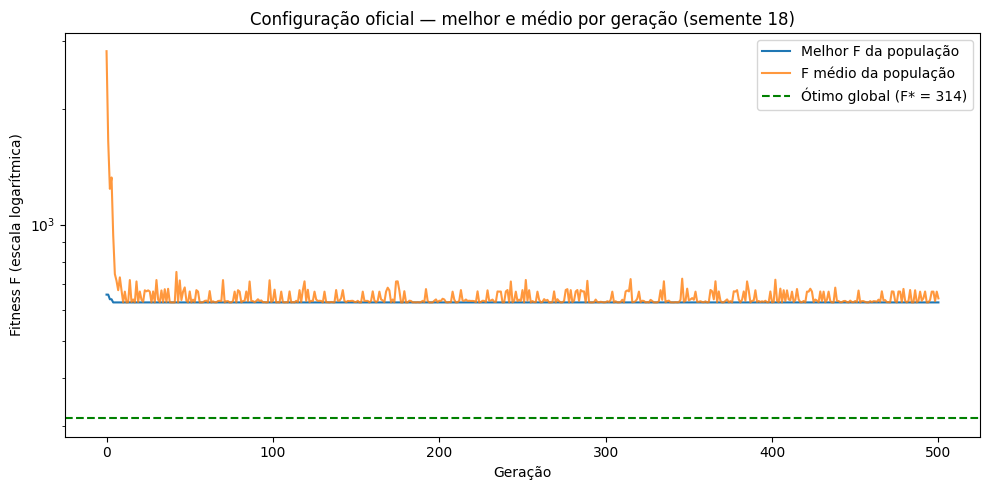

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist_melhor_oficial, label="Melhor F da população")
ax.plot(hist_medio_oficial, label="F médio da população", alpha=0.8)
ax.axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
ax.set_yscale("log")
ax.set_xlabel("Geração")
ax.set_ylabel("Fitness F (escala logarítmica)")
ax.set_title(f"Configuração oficial — melhor e médio por geração (semente {SEMENTE_EXEMPLO})")
ax.legend()
plt.tight_layout()
plt.show()

**Leitura da execução com a semente 18.** O AG encontrou os 5 professores de menor custo (custo-base R\$ 314, o mesmo do ótimo). Porém, em 3 dos 5 dias alocou disciplinas que o professor nunca ministrou, e o fator ×2 leva a F = 628, o dobro do ótimo. O melhor F se estabilizou na geração 4 e não mudou até a geração 500. No gráfico, o F médio da população cai para perto do melhor F nas primeiras gerações e passa a oscilar rente a ele: a população passa a ser formada quase só por cópias e pequenas variações da mesma solução.

**Por que a busca para em F = 628:**

1. A partir de uma solução com F = 628, corrigir **uma** disciplina não qualificada não reduz F enquanto restar outra, porque o fator ×2 continua valendo. A melhoria exige várias correções simultâneas (nesta execução, 3), e as soluções intermediárias não são recompensadas pelo fitness.
2. Essas soluções intermediárias empatam com a elite (F = 628). A ordenação do Python é estável: em caso de empate, mantém na frente os indivíduos que já estavam na elite. Por isso, as variações não entram na elite, e a elite só muda quando surge um indivíduo **estritamente** melhor.
3. Com mutação de 10% e reprodução restrita à elite, esse indivíduo estritamente melhor raramente aparece.

## 8. Item 7 — Estudo de parâmetros com 30 sementes

Uma única execução não basta para comparar configurações de um algoritmo estocástico. Por isso, cada configuração foi executada com as **mesmas 30 sementes (0 a 29)**. Isso torna a comparação pareada: para uma dada semente, as configurações partem do mesmo gerador de números aleatórios.

**Desenho do estudo:** a partir da configuração oficial, cada parâmetro é alterado **isoladamente** — mutação (20%, 30%, 40%), elitismo (10%, 30%), gerações (1000) e população (120). Por fim, a configuração proposta (população 120 + mutação 30%) é avaliada. O enunciado cita elitismo, mutação e gerações; a população foi incluída como parâmetro adicional.

**Métricas por configuração (sobre as 30 execuções):** melhor e pior F final; média, mediana e desvio padrão amostral do F final; quantas execuções atingiram o ótimo global F*; e geração média de convergência.

*Observação: esta célula executa 270 rodadas do AG e pode levar alguns minutos.*

In [11]:
SEMENTES = list(range(30))


def configuracao(pop=60, elit=0.20, mut=0.10, ger=500):
    return {"tamanho_populacao": pop, "elitismo": elit, "probabilidade_mutacao": mut, "numero_geracoes": ger}


def executar_experimento(config):
    resultados = []
    for semente in SEMENTES:
        random.seed(semente)
        melhor, fitness, hist_melhor, _ = genetico(professores, cromossomo_inicial, **config)
        resultados.append({"semente": semente, "melhor": melhor, "fitness": fitness,
                           "convergencia": geracao_de_convergencia(hist_melhor), "hist_melhor": hist_melhor})
    return resultados


def resumir(resultados):
    fitness = [r["fitness"] for r in resultados]
    return {
        "Melhor F": min(fitness),
        "Pior F": max(fitness),
        "Média": statistics.mean(fitness),
        "Mediana": statistics.median(fitness),
        "Desvio padrão": statistics.stdev(fitness),
        "Atingiu o ótimo": f"{sum(abs(f - OTIMO_GLOBAL) < 1e-9 for f in fitness)}/{len(fitness)}",
        "Geração média de convergência": statistics.mean(r["convergencia"] for r in resultados),
    }


NOME_OFICIAL = "Oficial (pop 60, elit 20%, mut 10%, 500 ger.)"
NOME_PROPOSTA = "Proposta (pop 120, mut 30%)"
CONFIGURACOES = {
    NOME_OFICIAL: configuracao(),
    "Mutação 20%": configuracao(mut=0.20),
    "Mutação 30%": configuracao(mut=0.30),
    "Mutação 40%": configuracao(mut=0.40),
    "Elitismo 10%": configuracao(elit=0.10),
    "Elitismo 30%": configuracao(elit=0.30),
    "1000 gerações": configuracao(ger=1000),
    "População 120": configuracao(pop=120),
    NOME_PROPOSTA: configuracao(pop=120, mut=0.30),
}
assert CONFIGURACOES[NOME_OFICIAL] == CONFIG_OFICIAL

resultados_por_config = {nome: executar_experimento(cfg) for nome, cfg in CONFIGURACOES.items()}

tabela_estudo = pd.DataFrame.from_dict(
    {nome: resumir(res) for nome, res in resultados_por_config.items()}, orient="index")
tabela_estudo.index.name = "Configuração (30 sementes cada)"
tabela_estudo.round(1)

,Melhor F,Pior F,Média,Mediana,Desvio padrão,Atingiu o ótimo,Geração média de convergência
Configuração (30 sementes cada),,,,,,,
"Oficial (pop 60, elit 20%, mut 10%, 500 ger.)",314.0,628.0,534.9,628.0,137.1,2/30,23.5
Mutação 20%,314.0,628.0,539.5,628.0,138.3,1/30,18.6
Mutação 30%,314.0,628.0,530.0,628.0,141.9,4/30,9.9
Mutação 40%,314.0,628.0,530.1,628.0,141.7,5/30,11.8
Elitismo 10%,314.0,628.0,544.7,628.0,131.4,2/30,24.5
Elitismo 30%,314.0,628.0,508.3,628.0,149.3,2/30,54.0
1000 gerações,314.0,628.0,534.9,628.0,137.1,2/30,23.5
População 120,314.0,628.0,449.1,335.0,150.7,6/30,29.4
"Proposta (pop 120, mut 30%)",314.0,628.0,474.0,482.0,156.7,6/30,15.5


**Leitura do estudo (30 execuções por configuração, sementes 0 a 29).** Os resultados são empíricos e dependem das sementes e do número de execuções. Com 30 execuções, diferenças de poucas execuções na coluna "Atingiu o ótimo" (ex.: 2/30 × 5/30) estão dentro do que o acaso pode produzir.

- **Todas as configurações:** o melhor F foi 314 (o ótimo) e o pior foi 628 (o platô descrito na seção 7). O que muda entre elas é quantas execuções escapam do platô.
- **Gerações (500 → 1000):** resultado idêntico ao da configuração oficial nas 30 sementes, ou seja, nenhuma execução melhorou depois da geração 500. Em média, o melhor F se estabiliza por volta da geração 24, muito antes do limite, então mais gerações não trazem ganho.
- **Mutação (10% → 20%, 30%, 40%):** efeito pequeno. A média do F final ficou entre 530,0 e 539,5 em todas as variações, a mediana continuou em 628 e as execuções no ótimo variaram de 1/30 a 5/30. Com 30–40%, o melhor F se estabilizou mais cedo (≈ 10–12 gerações, em média).
- **Elitismo (10% / 30%):** com 30%, a média caiu para 508,3 e a estabilização ficou mais lenta (54 gerações), mas a mediana continuou 628 e só 2/30 execuções atingiram o ótimo. Com 10%, a média subiu para 544,7.
- **População (60 → 120):** foi a alteração isolada com maior efeito nestas 30 execuções: média 449,1, mediana 335 e 6/30 execuções no ótimo. Uma população maior testa mais combinações antes da estagnação e aumenta a chance de encontrar uma grade sem penalidades.

**Resposta ao item 7.**

- **Parâmetros citados no enunciado (elitismo, mutação, gerações):** nenhum mudou o comportamento de forma consistente. Aumentar as gerações não teve efeito, e mutação e elitismo produziram diferenças pequenas.
- **Tamanho da população:** foi a alteração com maior efeito observado.
- **Proposta levada ao item 8:** aumentar a população (60 → 120) e, junto, a mutação (10% → 30%), para manter mais variação genética durante a busca. Elitismo (20%) e gerações (500) ficam como no enunciado.

## 9. Item 8 — Configuração proposta × configuração oficial

A configuração proposta — **população 120, mutação 30%**, mantendo elitismo de 20% e 500 gerações — é tratada aqui como **proposta experimental**. A comparação usa as mesmas 30 sementes da seção 8.

Além das estatísticas descritivas, dois testes simples verificam se as diferenças observadas poderiam ser explicadas pelo acaso:
- o **teste de Wilcoxon pareado** compara o F final das duas configurações semente a semente;
- o **teste exato de Fisher** compara a proporção de execuções que atingiram o ótimo.

In [12]:
def descrever(config, resultados):
    return {"População": config["tamanho_populacao"], "Elitismo": f"{config['elitismo']:.0%}",
            "Mutação": f"{config['probabilidade_mutacao']:.0%}", "Gerações": config["numero_geracoes"],
            **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in resumir(resultados).items()}}


res_oficial = resultados_por_config[NOME_OFICIAL]
res_proposta = resultados_por_config[NOME_PROPOSTA]

comparacao = pd.DataFrame({
    "Oficial": descrever(CONFIGURACOES[NOME_OFICIAL], res_oficial),
    "Proposta": descrever(CONFIGURACOES[NOME_PROPOSTA], res_proposta),
})
comparacao.index.name = "Métrica"
display(comparacao)

por_semente = pd.DataFrame({
    "F oficial": [r["fitness"] for r in res_oficial],
    "F proposta": [r["fitness"] for r in res_proposta],
}, index=pd.Index(SEMENTES, name="Semente"))
display(por_semente.T)

diferenca = por_semente["F proposta"] - por_semente["F oficial"]
print(f"Comparação pareada por semente: proposta com F menor em {(diferenca < 0).sum()}, "
      f"igual em {(diferenca == 0).sum()} e maior em {(diferenca > 0).sum()} das {len(SEMENTES)} sementes.")

# consistência: a semente 18 da configuração oficial reproduz a execução detalhada da seção 7
assert res_oficial[SEMENTE_EXEMPLO]["fitness"] == fitness_oficial

,Oficial,Proposta
Métrica,,
População,60,120
Elitismo,20%,20%
Mutação,10%,30%
Gerações,500,500
Melhor F,314.0,314.0
Pior F,628.0,628.0
Média,534.9,474.03
Mediana,628.0,482.0
Desvio padrão,137.15,156.67


Semente,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
F oficial,628.0,340.0,324.0,628.0,314.0,314.0,628.0,321.0,628.0,628.0,628.0,628.0,332.0,628.0,628.0,333.0,405.0,628.0,628.0,628.0,628.0,628.0,480.0,628.0,628.0,628.0,628.0,628.0,324.0,628.0
F proposta,628.0,320.0,628.0,314.0,325.0,628.0,628.0,628.0,320.0,628.0,628.0,628.0,314.0,314.0,628.0,321.0,320.0,320.0,314.0,628.0,628.0,336.0,314.0,628.0,628.0,325.0,628.0,314.0,628.0,330.0


Comparação pareada por semente: proposta com F menor em 14, igual em 11 e maior em 5 das 30 sementes.


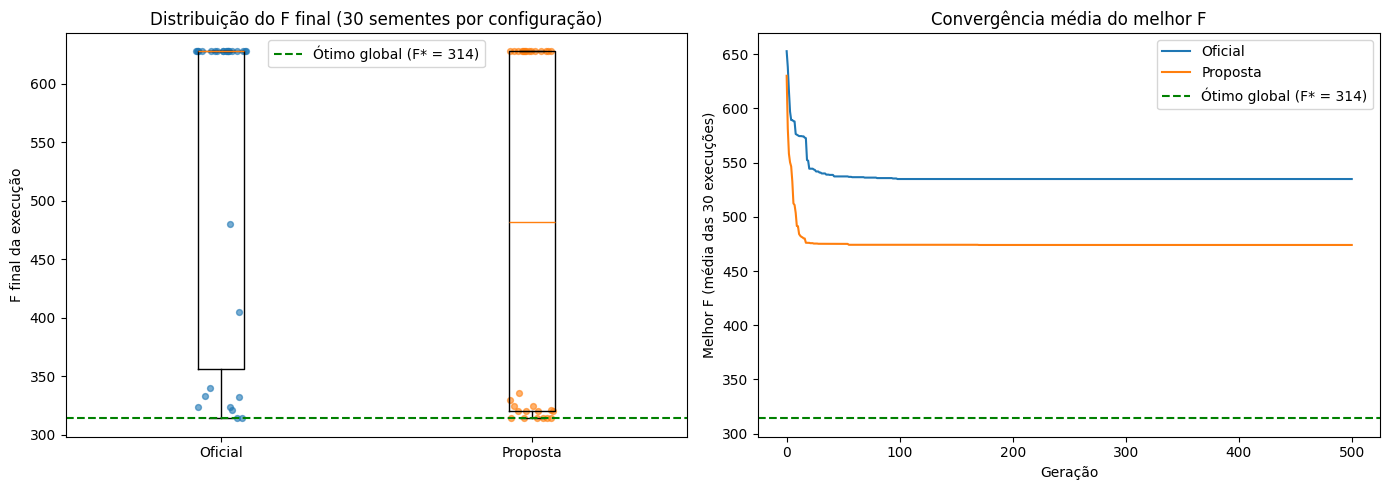

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# distribuição do F final nas 30 execuções
dados = [por_semente["F oficial"], por_semente["F proposta"]]
axes[0].boxplot(dados, tick_labels=["Oficial", "Proposta"])
rng = np.random.default_rng(0)  # apenas para espalhar horizontalmente os pontos sobrepostos
for i, valores in enumerate(dados, start=1):
    axes[0].scatter(i + rng.uniform(-0.08, 0.08, len(valores)), valores, alpha=0.6, s=18)
axes[0].axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
axes[0].set_ylabel("F final da execução")
axes[0].set_title("Distribuição do F final (30 sementes por configuração)")
axes[0].legend()

# média, nas 30 execuções, do melhor F em cada geração
for nome, rotulo in [(NOME_OFICIAL, "Oficial"), (NOME_PROPOSTA, "Proposta")]:
    curvas = np.array([r["hist_melhor"] for r in resultados_por_config[nome]])
    axes[1].plot(curvas.mean(axis=0), label=rotulo)
axes[1].axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
axes[1].set_xlabel("Geração")
axes[1].set_ylabel("Melhor F (média das 30 execuções)")
axes[1].set_title("Convergência média do melhor F")
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
# Wilcoxon pareado: sementes com F igual nas duas configurações são descartadas (padrão do scipy)
teste_pareado = wilcoxon(por_semente["F oficial"], por_semente["F proposta"])
acertos = {col: int(sum(abs(f - OTIMO_GLOBAL) < 1e-9 for f in por_semente[col])) for col in por_semente}
teste_taxa = fisher_exact([[acertos["F oficial"], len(SEMENTES) - acertos["F oficial"]],
                           [acertos["F proposta"], len(SEMENTES) - acertos["F proposta"]]])
print(f"Wilcoxon pareado (F final, oficial x proposta, {len(SEMENTES)} sementes): p = {teste_pareado.pvalue:.3f}")
print(f"Fisher exato (atingiu o ótimo: {acertos['F oficial']}/{len(SEMENTES)} x "
      f"{acertos['F proposta']}/{len(SEMENTES)}): p = {teste_taxa.pvalue:.3f}")

Wilcoxon pareado (F final, oficial x proposta, 30 sementes): p = 0.076
Fisher exato (atingiu o ótimo: 2/30 x 6/30): p = 0.254


**Interpretação (item 8).** Nas 30 execuções realizadas, a configuração proposta apresentou, em relação à oficial:

- média do F final menor (474,03 × 534,9) e mediana menor (482 × 628);
- mais execuções terminando no ótimo global (6/30 × 2/30);
- estabilização mais cedo (15,47 × 23,53 gerações, em média);
- o mesmo melhor (314) e o mesmo pior (628) resultado;
- desvio padrão maior (156,67 × 137,15), reflexo de uma distribuição dividida entre execuções próximas do ótimo e execuções presas em 628 (boxplot);
- na comparação semente a semente, F menor em 14, igual em 11 e maior em 5 das 30 sementes.

**Alcance destas conclusões:**

1. **A diferença não é estatisticamente conclusiva com 30 execuções.** O Wilcoxon pareado (p = 0,076) e o Fisher exato (p = 0,254) não rejeitam, ao nível de 5%, a hipótese de desempenho igual. A tendência observada favorece a proposta, mas confirmá-la exigiria mais execuções.
2. **O efeito observado parece vir da população, e não da mutação.** Na seção 8, aumentar só a população para 120 (com mutação de 10%) resultou em média 449,1 e mediana 335, com os mesmos 6/30 no ótimo. Nestas sementes, a mutação de 30% não trouxe benefício adicional observável.
3. **Nenhuma das duas configurações resolve o problema de forma confiável.** Nas duas, a maioria das execuções termina fora do ótimo, em geral no platô F = 628.

## 10. Conclusão

- **Itens 1 a 5.** A tabela do enunciado foi transcrita para `tab_professores.txt` e lida para um dicionário. A função de fitness implementa a fórmula do enunciado: soma dos custos dos 5 dias × fatores ×2, ×1,5 e ×5, que podem se combinar. A mutação (1 gene, dentro do domínio) e o cruzamento (1 ponto de corte variável, dois filhos) reproduzem os exemplos do enunciado. O AG usa o cromossomo inicial dado, população de tamanho fixo e elitismo.
- **Ótimo global.** F\* = 314, demonstrado por um limite inferior válido para qualquer cromossomo e por uma grade sem penalidades que o atinge (professores 3, 4, 6, 7 e 8).
- **Item 6 (configuração oficial).** Nas 30 execuções, só 2 atingiram o ótimo, e a mediana do F final foi 628. As execuções que ficam em F = 628 usam exatamente os 5 professores mais baratos, mas alocam ao menos um deles a uma disciplina que nunca ministrou. Elas estagnam porque corrigir uma disciplina de cada vez não melhora F, e a elite só muda quando surge um indivíduo estritamente melhor.
- **Item 7.** Aumentar as gerações não teve efeito (resultados idênticos com 1000). Mutação e elitismo tiveram efeito pequeno. O tamanho da população foi o parâmetro com maior efeito observado.
- **Item 8.** Nas 30 execuções, a configuração proposta (população 120, mutação 30%) apresentou média e mediana menores e mais execuções no ótimo (6/30 × 2/30) que a oficial. A diferença, porém, não é estatisticamente conclusiva com esse número de execuções. Só aumentar a população teve resultado semelhante: a mesma taxa de ótimo, com média e mediana menores.

**Reprodutibilidade.** Todos os resultados deste notebook são empíricos e reprodutíveis. Cada execução do AG fixa sua semente (`random.seed`), e as mesmas sementes (0 a 29) foram usadas em todas as configurações. Outras sementes produzirão números diferentes.